# 14. XGBoost Regressor

**Project** · Electricity Demand Prediction  
**Problem type** · Regression

This dataset is synthetic and designed for education. Keep its predictions within the exercise. Any real-world financial, medical, safety, educational or employment decision requires independent evidence and validation.

Start with Sections 1–9 for your first model. Then try parameter tuning and the interview exercises. Run the code cells in order because each step uses results from earlier cells.

## 1. Introduction

Boosted regression adds small tree corrections to a running numerical prediction. It can estimate electricity demand from temperature, humidity and time of day, including separate heating and cooling effects. This exercise is a snapshot regression project.

By the end, you can implement the pipeline, explain how it predicts and use holdout results to identify where it struggles.

## 2. Understand the Dataset

Demand starts at 470 MW and adds squared temperature deviation from 21 °C, Gaussian-shaped morning and evening peaks, industrial activity, and a hot-weather humidity interaction. Holidays subtract 65 MW and Gaussian noise with standard deviation 43 MW is added. Industrial activity depends partly on hour and day type. Rows are independent snapshots without timestamps.

| Column | Type | Units or values | Meaning |
| --- | --- | --- | --- |
| `temperature_c` | decimal | °C | Outdoor temperature |
| `humidity_pct` | decimal | percent | Relative humidity |
| `hour_of_day` | integer | hour 0 to 23 | Hour in local time |
| `day_type` | string | Weekday, Weekend or Holiday | Calendar day category |
| `industrial_activity_pct` | decimal | percent | Synthetic industrial activity index |
| `electricity_demand_mw` | decimal | MW | Observed continuous outcome |

**Independent variables (X)** · `temperature_c`, `humidity_pct`, `hour_of_day`, `day_type`, `industrial_activity_pct`.

**Dependent variable (y)** · `electricity_demand_mw` is the continuous quantity to predict in MW. The preview shows the first 10 rows, dimensions and stored types. Blank features, where present, are intentional.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display

csv_name = "14_electricity_demand.csv"
csv_path = Path("../datasets") / csv_name

# Also look in the project folder or the location used for Colab uploads.
if not csv_path.is_file():
    csv_path = Path("datasets") / csv_name
if not csv_path.is_file():
    csv_path = Path("Machine_Learning_Complete_Guide/datasets") / csv_name
if not csv_path.is_file():
    csv_path = Path(csv_name)

df = pd.read_csv(csv_path, keep_default_na=False, na_values=[""])
print("Dataset shape:", df.shape)
display(df.head(10))
display(df.dtypes)

Dataset shape: (1500, 6)


,temperature_c,humidity_pct,hour_of_day,day_type,industrial_activity_pct,electricity_demand_mw
0,6.5,42.5,2,Weekend,41.6,844.04
1,15.4,41.0,21,Weekend,58.3,929.52
2,16.2,78.3,22,Weekend,57.7,872.37
3,5.0,41.5,0,Weekday,56.7,998.67
4,38.5,37.0,8,Weekday,99.1,1420.33
5,35.9,90.8,18,Weekday,100.0,1464.56
6,28.3,35.7,1,Weekday,69.7,838.57
7,11.2,39.7,10,Weekday,71.7,997.00
8,29.0,50.6,6,Weekday,71.4,968.62
9,25.9,82.6,8,Weekend,79.1,963.09


temperature_c              float64
humidity_pct               float64
hour_of_day                  int64
day_type                       str
industrial_activity_pct    float64
electricity_demand_mw      float64
dtype: object

## 3. Mathematical Understanding

Start with score $F_0(x)$, then update $F_t(x)=F_{t-1}(x)+\eta f_t(x)$. Here $x$ is a demand profile, $t$ the boosting round, $f_t$ the new tree and $\eta$ the learning rate. With the half-squared loss $\tfrac12(y-F)^2$, the gradient is $g=F-y$, the Hessian is $h=1$, and the negative gradient is the residual $y-F$. For a leaf, XGBoost uses $w=-G/(H+\lambda)$ when L1 regularization is zero, with summed gradients $G$, summed Hessians $H$ and L2 penalty $\lambda$.

Suppose a leaf contains three rows with residuals $40$, $20$ and $-10$ MW. Then $G=-50$ and $H=3$. With $\lambda=2$, the leaf score is $10$ MW. Learning rate $0.1$ adds $1$ MW to the running estimate for rows routed to that leaf.

[XGBoost model tutorial](https://xgboost.readthedocs.io/en/stable/tutorials/model.html)

## 4. Working Principle

Start with a constant reference estimate. Compute errors on the training set, find feature cutoffs that identify groups needing similar corrections, and add a shrunken correction tree. Repeat using the updated scores. At prediction time sum the initial estimate and all learned contributions.

| Step | Value |
| --- | --- |
| Sum of residuals | 50 MW |
| Leaf score with L2 penalty | 10 MW |
| Shrunken correction | 1 MW |

**Workflow diagram**

`Raw input` → `Imputed numeric values and any category indicators` → `Sequentially adds regularized trees to reduce numeric error` → `Estimate in MW`.

## 5. Dataset Exploration

The first and last rows verify parsing. Shape and info reveal size, stored types and non-missing counts. Summary statistics show typical values, ranges and spread. Missingness and duplicate counts identify possible cleanup needs. The target plot shows the range and shape of the outcome. Feature plots show variation. Pearson correlation measures linear association. Watch for nonlinear trends even if a linear association is present. The features and evaluation design are fixed before modeling.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
TARGET = "electricity_demand_mw"
FEATURES = ["temperature_c","humidity_pct","hour_of_day","day_type","industrial_activity_pct"]
NUMERIC = ["temperature_c","humidity_pct","hour_of_day","industrial_activity_pct"]
CATEGORICAL = ["day_type"]
SEED = 42

In [3]:
df.info()
display(df.head())
display(df.tail())
display(df.describe(include="all").T)
display(pd.DataFrame({"Missing": df.isna().sum(), "Missing %": 100 * df.isna().mean()}).round(1))
print("Exact duplicate rows:", df.duplicated().sum())
print("Repeated feature rows:", df.duplicated(subset=FEATURES).sum())

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 6 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   temperature_c            1500 non-null   float64
 1   humidity_pct             1470 non-null   float64
 2   hour_of_day              1500 non-null   int64  
 3   day_type                 1470 non-null   str    
 4   industrial_activity_pct  1500 non-null   float64
 5   electricity_demand_mw    1500 non-null   float64
dtypes: float64(4), int64(1), str(1)
memory usage: 80.7 KB


,temperature_c,humidity_pct,hour_of_day,day_type,industrial_activity_pct,electricity_demand_mw
0,6.5,42.5,2,Weekend,41.6,844.04
1,15.4,41.0,21,Weekend,58.3,929.52
2,16.2,78.3,22,Weekend,57.7,872.37
3,5.0,41.5,0,Weekday,56.7,998.67
4,38.5,37.0,8,Weekday,99.1,1420.33


,temperature_c,humidity_pct,hour_of_day,day_type,industrial_activity_pct,electricity_demand_mw
1495,22.2,72.1,11,Weekday,100.0,844.14
1496,26.3,80.5,15,Weekday,76.9,921.02
1497,36.5,75.5,23,Weekday,57.0,1088.36
1498,7.6,78.3,10,Weekend,81.2,1128.74
1499,32.8,65.1,10,Weekend,55.8,1070.98


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
temperature_c,1500.0,NaN,NaN,NaN,21.800867,10.12694,4.0,13.3,21.9,30.4,39.0
humidity_pct,1470.0,NaN,NaN,NaN,59.281633,19.985681,25.0,42.125,60.1,75.975,94.9
hour_of_day,1500.0,NaN,NaN,NaN,11.206667,7.024399,0.0,5.0,11.0,17.0,23.0
day_type,1470,3,Weekday,1057,NaN,NaN,NaN,NaN,NaN,NaN,NaN
industrial_activity_pct,1500.0,NaN,NaN,NaN,68.440733,16.440031,30.3,55.2,68.7,82.0,100.0
electricity_demand_mw,1500.0,NaN,NaN,NaN,958.63826,148.85552,526.27,853.22,950.865,1059.78,1464.56


,Missing,Missing %
temperature_c,0,0.0
humidity_pct,30,2.0
hour_of_day,0,0.0
day_type,30,2.0
industrial_activity_pct,0,0.0
electricity_demand_mw,0,0.0


Exact duplicate rows: 0
Repeated feature rows: 0


### Plot the target

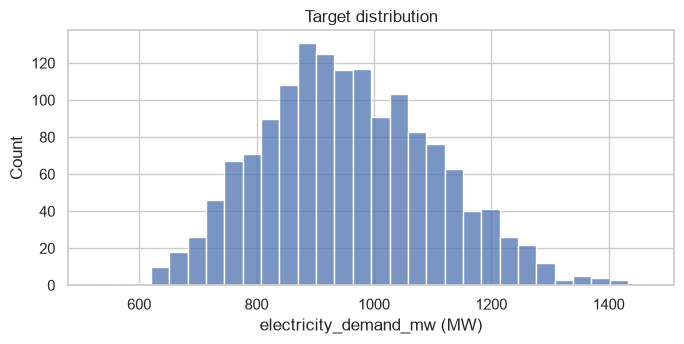

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.6))
sns.histplot(data=df, x=TARGET, bins=30, ax=ax)
ax.set_xlabel("electricity_demand_mw (MW)")
ax.set_title("Target distribution")
fig.tight_layout()
plt.show()

### Look at the input features

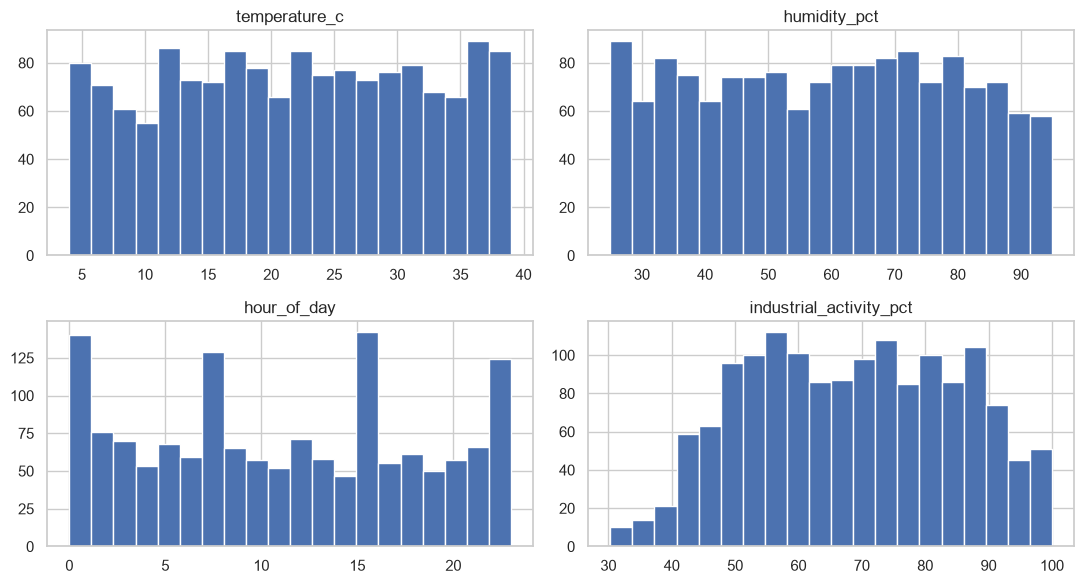

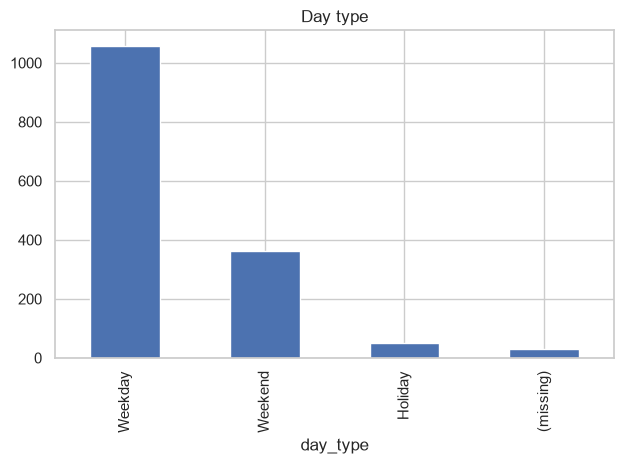

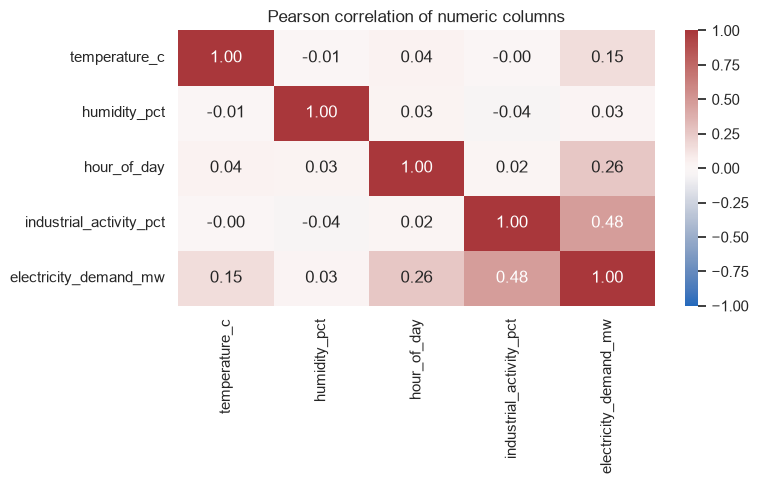

In [5]:
df[NUMERIC].hist(figsize=(11, 6), bins=20)
plt.tight_layout()
plt.show()

df["day_type"].fillna("(missing)").value_counts().plot.bar()
plt.title("Day type")
plt.tight_layout()
plt.show()

correlation_columns = NUMERIC + [TARGET]
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(df[correlation_columns].corr(), annot=True, fmt=".2f", cmap="vlag",
            center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Pearson correlation of numeric columns")
fig.tight_layout()
plt.show()

## 6. Data Preprocessing

Select the input columns and target explicitly. A seeded random split suits these independently generated rows. The numeric branch fills blanks using training medians. The categorical branch fills blanks with the most common training level and one-hot encodes levels. An unseen level becomes an all-zero block. Tree splits use the ordering of values, so scaling is unnecessary. The pipeline fits each preprocessing step after the split and repeats it in each training fold.

Exact and feature-only duplicate counts are listed above. Identical measurements with distinct outcomes can represent legitimate observations.

### 1. Choose the inputs and target

In [6]:
# X contains the inputs. y contains the answer for each row.
X = df[FEATURES]
y = df[TARGET]

### 2. Split the rows into training and test sets

In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 1200
Test rows: 300


### 3. Prepare the columns

The next cell sets up the cleaning steps. They learn their values later, when you fit the model.

In [8]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Fill blank numbers with the training median.
numeric_preprocess = SimpleImputer(strategy="median")

# Fill blank categories, then make one indicator column per category.
category_preprocess = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocess = ColumnTransformer(
    [
        ("numeric", numeric_preprocess, NUMERIC),
        ("categorical", category_preprocess, CATEGORICAL),
    ],
    verbose_feature_names_out=False,
)

## 7. Model Implementation

`objective='reg:squarederror'` targets squared loss. `n_estimators` sets the number of rounds and `learning_rate` shrinks each round. `max_depth` controls the interactions available to one tree. `reg_lambda` shrinks terminal scores toward zero.

- The estimator import provides the algorithm implementation.
- `Pipeline` joins preprocessing and the model in execution order.
- `fit(X_train, y_train)` learns transformations and parameters from training rows.
- `predict(...)` applies the fitted steps to new rows. The first holdout row gives a preview before scoring the entire split.

### Create the model

In [9]:
from xgboost import XGBRegressor

estimator = XGBRegressor(objective="reg:squarederror", n_estimators=125, max_depth=3, learning_rate=0.08, reg_lambda=2.0, tree_method="hist", random_state=SEED, n_jobs=2)
model = Pipeline([
    ("preprocess", preprocess),
    ("model", estimator),
])

### Fit on the training rows

In [10]:
# Learn from the training rows.
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['temperature_c','humidity_pct','hour_of_day','day_type', 'industrial_activity_pct']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not pref

### Predict on the test rows

In [11]:
# Predict using the held-out inputs.
predictions = model.predict(X_test)
display(X_test.head(1))
print(f"Example prediction: {predictions[0]:,.2f} MW")

,temperature_c,humidity_pct,hour_of_day,day_type,industrial_activity_pct
1116,29.5,85.3,1,Weekday,90.0


Example prediction: 986.63 MW


## 8. Model Evaluation

Let $y_i$ be the actual test value for row $i$, $\hat y_i$ its prediction, $e_i=y_i-\hat y_i$ its residual, $n$ the number of test rows and $\bar y$ the test target mean.

| Metric | Formula | Interpretation |
| --- | --- | --- |
| Mean absolute error | $\mathrm{MAE}=n^{-1}\sum_i\lvert e_i\rvert$ | Mean absolute miss in the target unit. Lower is better. |
| Mean squared error | $\mathrm{MSE}=n^{-1}\sum_i e_i^2$ | Mean squared miss in squared units. It puts more weight on large errors. Lower is better. |
| Root mean squared error | $\mathrm{RMSE}=\sqrt{\mathrm{MSE}}$ | Error on the target scale that emphasizes large misses. Lower is better. |
| Coefficient of determination | $R^2=1-\sum_i e_i^2/\sum_i(y_i-\bar y)^2$ | Higher is better. One is a perfect fit, zero matches the squared error of the test mean, and negative means more error than that reference. |

The baseline predicts the **training** target mean, so its test R² may be slightly negative. Compare MAE and RMSE to it in the table below.

**Target unit** · MW.

In [12]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score

initial_metrics = {
    "MAE": mean_absolute_error(y_test, predictions),
    "MSE": mean_squared_error(y_test, predictions),
    "RMSE": root_mean_squared_error(y_test, predictions),
    "R²": r2_score(y_test, predictions),
}
display(pd.Series(initial_metrics, name="Test score").round(3))

MAE       35.414
MSE     1964.889
RMSE      44.327
R²         0.916
Name: Test score, dtype: float64

### Compare with a simple baseline

In [13]:
# A baseline predicts the mean training target for every row.
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)
baseline_predictions = baseline.predict(X_test)

baseline_metrics = {
    "MAE": mean_absolute_error(y_test, baseline_predictions),
    "MSE": mean_squared_error(y_test, baseline_predictions),
    "RMSE": root_mean_squared_error(y_test, baseline_predictions),
    "R²": r2_score(y_test, baseline_predictions),
}
display(pd.DataFrame([baseline_metrics, initial_metrics], index=["Baseline", "Model"]).round(3))

,MAE,MSE,RMSE,R²
Baseline,126.915,23399.557,152.969,-0.005
Model,35.414,1964.889,44.327,0.916


## 9. Visualizations

Compare estimated and measured outcomes against the 45-degree line. A point above that line is an overestimate. In the residual panel, points above zero are underestimates. A systematic curve suggests missing structure, and widening scatter suggests changing error spread.

The hour profile keeps temperature, humidity and activity fixed to show the model’s response to hour on one weekday profile. The points form a conditional slice through the model, and the dataset contains independently sampled rows. The gain plot shows which encoded features contributed to splits.

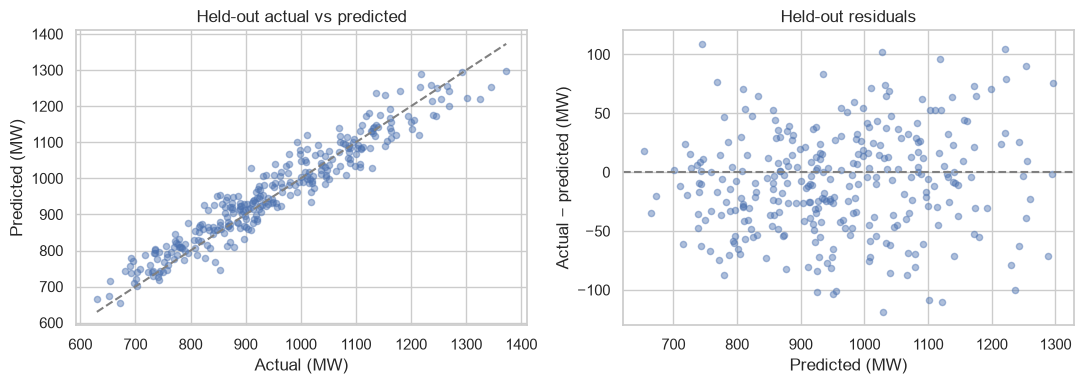

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
limits = [min(y_test.min(), predictions.min()), max(y_test.max(), predictions.max())]
axes[0].scatter(y_test, predictions, s=20, alpha=0.45)
axes[0].plot(limits, limits, color="grey", linestyle="--")
axes[0].set(xlabel="Actual (MW)", ylabel="Predicted (MW)", title="Held-out actual vs predicted")
axes[1].scatter(predictions, y_test - predictions, s=20, alpha=0.45)
axes[1].axhline(0, color="grey", linestyle="--")
axes[1].set(xlabel="Predicted (MW)", ylabel="Actual − predicted (MW)", title="Held-out residuals")
fig.tight_layout()
plt.show()

### A closer look at this model

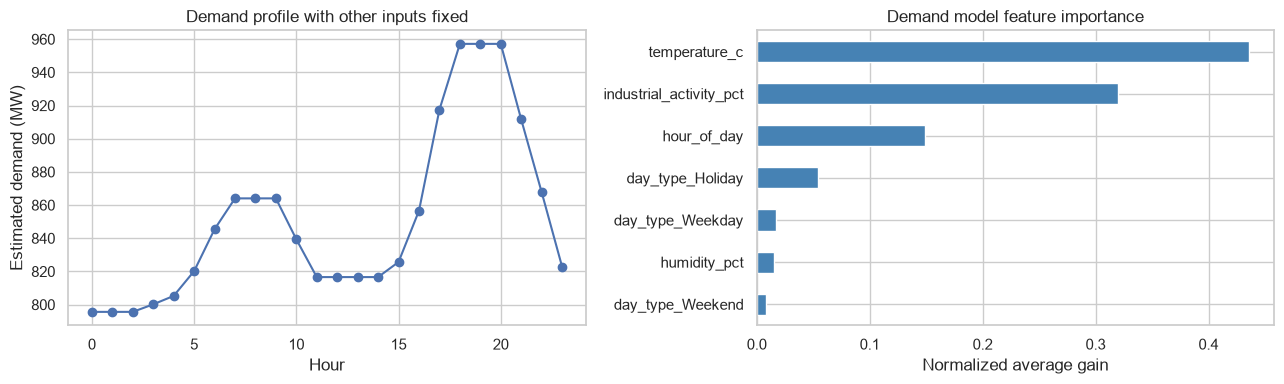

In [15]:
profile = pd.DataFrame({
    "temperature_c": X_train["temperature_c"].median(),
    "humidity_pct": X_train["humidity_pct"].median(),
    "hour_of_day": np.arange(24),
    "day_type": "Weekday",
    "industrial_activity_pct": X_train["industrial_activity_pct"].median(),
})
booster = model.named_steps["model"]
gain = pd.Series(booster.feature_importances_, index=model.named_steps["preprocess"].get_feature_names_out())
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(profile["hour_of_day"], model.predict(profile), marker="o")
axes[0].set(xlabel="Hour", ylabel="Estimated demand (MW)", title="Demand profile with other inputs fixed")
gain.sort_values().plot.barh(ax=axes[1], color="steelblue")
axes[1].set(xlabel="Normalized average gain", title="Demand model feature importance")
fig.tight_layout()
plt.show()

## 10. Hyperparameter Tuning

GridSearchCV tries the grid with three shuffled folds within the training data. Each candidate gets a freshly fitted pipeline per fold. Rank by lowest RMSE. The scorer negates RMSE so that the best score ranks first. `refit=True` fits the winner on all training rows. Use the CV ranks to choose parameters and the holdout to report performance.

`objective='reg:squarederror'` targets squared loss. `n_estimators` sets the number of rounds and `learning_rate` shrinks each round. `max_depth` controls the interactions available to one tree. `reg_lambda` shrinks terminal scores toward zero.

[GridSearchCV documentation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)

### Set up the candidate settings

In [16]:
from sklearn.model_selection import GridSearchCV, KFold

param_grid = {"model__n_estimators": [80, 150], "model__learning_rate": [0.05, 0.12],
 "model__max_depth": [2, 4], "model__reg_lambda": [1, 5]}
validation = KFold(n_splits=3, shuffle=True, random_state=SEED)
search = GridSearchCV(model, param_grid, scoring="neg_root_mean_squared_error", cv=validation,
                      refit=True, n_jobs=1, error_score="raise")

### Search using training rows

In [17]:
search.fit(X_train, y_train)
tuned_model = search.best_estimator_
results = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
results["Mean fold RMSE"] = -results["mean_test_score"]
print("Best training-CV parameters:", search.best_params_)
display(results[["rank_test_score", "Mean fold RMSE", "std_test_score", "params"]].head().round(3))

Best training-CV parameters: {'model__learning_rate': 0.12, 'model__max_depth': 2, 'model__n_estimators': 150, 'model__reg_lambda': 1}


,rank_test_score,Mean fold RMSE,std_test_score,params
10,1,46.970,0.188,"{'model__learning_rate': 0.12, 'model__max_dep..."
11,2,47.666,0.218,"{'model__learning_rate': 0.12, 'model__max_dep..."
12,3,50.123,0.326,"{'model__learning_rate': 0.12, 'model__max_dep..."
14,4,50.365,0.674,"{'model__learning_rate': 0.12, 'model__max_dep..."
15,5,50.415,0.589,"{'model__learning_rate': 0.12, 'model__max_dep..."


### Compare the models on the test set

In [18]:
tuned_predictions = tuned_model.predict(X_test)

tuned_metrics = {
    "MAE": mean_absolute_error(y_test, tuned_predictions),
    "MSE": mean_squared_error(y_test, tuned_predictions),
    "RMSE": root_mean_squared_error(y_test, tuned_predictions),
    "R²": r2_score(y_test, tuned_predictions),
}
comparison = pd.DataFrame(
    [baseline_metrics, initial_metrics, tuned_metrics],
    index=["Baseline", "First model", "Tuned model"],
)
display(comparison.round(3))

,MAE,MSE,RMSE,R²
Baseline,126.915,23399.557,152.969,-0.005
First model,35.414,1964.889,44.327,0.916
Tuned model,34.906,1864.074,43.175,0.920


## 11. Real-World Prediction

Pass three new examples to the CV-selected pipeline. Read the estimates in MW and compare the scenarios to see how the fitted model responds.

### Enter three new examples

In [19]:
examples = pd.DataFrame([
    [16, 55, 3, 'Weekend', 38],
    [30, 72, 19, 'Weekday', 84],
    [8, 62, 8, 'Holiday', 48],
], columns=FEATURES)
display(examples)

,temperature_c,humidity_pct,hour_of_day,day_type,industrial_activity_pct
0,16,55,3,Weekend,38
1,30,72,19,Weekday,84
2,8,62,8,Holiday,48


### Make predictions

In [20]:
sample_inputs = examples
prediction_model = tuned_model
sample_predictions = prediction_model.predict(sample_inputs)
example_output = examples.copy()
example_output["Scenario"] = ["Quiet weekend overnight","Hot weekday around the evening peak","Cold holiday morning"]
example_output["Predicted electricity_demand_mw (MW)"] = sample_predictions.round(2)
display(example_output)

,temperature_c,humidity_pct,hour_of_day,day_type,industrial_activity_pct,Scenario,Predicted electricity_demand_mw (MW)
0,16,55,3,Weekend,38,Quiet weekend overnight,676.260010
1,30,72,19,Weekday,84,Hot weekday around the evening peak,1143.910034
2,8,62,8,Holiday,48,Cold holiday morning,875.260010


## 12. Limitations and Advantages

Boosting captures rich interactions and can outperform a single tree. It takes more tuning, its stepwise inputs complicate extrapolation, and extreme outcomes can affect squared loss. Few shallow trees can underfit. Many deep trees with a large learning rate can overfit. Use for nonlinear tabular estimates. For chronological forecasting, validate in time order and use only weather and activity values available at the forecast issue time.

## 13. Interview Preparation

### A. 30-second explanation

> I estimated synthetic electricity demand using gradient-boosted regression trees. Each round adds a shrunken tree contribution based on current residuals. I tuned the number and depth of trees jointly with learning rate and regularization, then measured holdout error in MW and checked the hour-of-day profile.

### B. 90-second technical explanation

> I estimated synthetic electricity demand using gradient-boosted regression trees. Each round adds a shrunken tree contribution based on current residuals. I tuned the number and depth of trees jointly with learning rate and regularization, then measured holdout error in MW and checked the hour-of-day profile. My target was electricity demand mw, and the inputs were temperature c, humidity pct, hour of day, day type, industrial activity pct. Start with a constant reference estimate. Compute errors on the training set, find feature cutoffs that identify groups needing similar corrections, and add a shrunken correction tree. Repeat using the updated scores. At prediction time sum the initial estimate and all learned contributions. I held out 20% of the rows and fitted preprocessing within each training fold. I measured MAE in MW and RMSE to see how much larger errors mattered. I compared the model with a training-mean predictor and inspected residuals. The inputs and labels were generated for teaching, so the holdout performance describes this exercise. For real data I would confirm which inputs are available at prediction time and build a split that reflects where the model will be used.

### C. Ten technical questions

1. **What is a weak learner here?** A small regression tree used for one update.
2. **What does the next tree learn under squared loss?** A regularized correction based on the current residuals.
3. **What is a Hessian?** The second derivative of the loss with respect to its current prediction.
4. **What are the inference steps?** Start from the fitted base score and add the contribution of every tree.
5. **What does a lower learning rate do?** It reduces each correction, often requiring more rounds.
6. **What does the L2 penalty do?** It shrinks leaf scores, especially when few examples support a leaf.
7. **Why use a histogram split method?** It searches over summarized feature bins for efficient tree construction.
8. **Is the hour profile a forecast series?** No. It is a conditional slice across independently sampled snapshots.
9. **Why evaluate RMSE along with MAE?** RMSE puts more weight on large MW misses.
10. **Can the model learn unrestricted trend extrapolation?** Tree cutoffs use learned regions and provide weak support for inputs beyond observed ranges.

### D. Five scenario questions

1. **A real dataset contains multiple years of hourly readings. How would you split?** Use forward-chaining validation and a final later test period.
2. **Realized industrial activity arrives after the forecast. What should the predictor use?** Use a version known at issue time, such as a schedule or forecast.
3. **The model misses holiday peaks. What would you check?** Inspect holiday sample size and subgroup residuals, then validate any richer calendar features.
4. **Training RMSE is near zero and test RMSE is large. What would you try?** Tune lower depth or fewer rounds and stronger regularization inside training validation.
5. **Heatwaves exceed the training range. What would you report?** Evaluate stress cases with observed extreme-weather data and consider features or models informed by demand physics.

### E. Three common mistakes

- Treating independently generated hours as a chronological series. Use the snapshot interpretation.
- Trying more rounds with no validation. Compare training-fold RMSE.
- Using actual future inputs in a forecasting evaluation. Use data available at forecast time.

### F. Complete project explanation

Use the measured scores in a short project walkthrough. Start with the problem, explain the pipeline and close with what the evaluation can support. This cell inserts results from the current run.

In [21]:
from IPython.display import Markdown

summary = (
    "I built a supervised regression project for electricity demand prediction using XGBoost Regressor. I generated 1,500 synthetic observations and used temperature c, humidity pct, hour of day, day type, industrial activity pct to predict electricity demand mw. I used a holdout and a preprocessing pipeline fitted within training folds. I compared the selected estimator with a simple baseline. "
    f"On the holdout, the CV-selected model achieved MAE {tuned_metrics['MAE']:,.2f} MW, "
    f"compared with {baseline_metrics['MAE']:,.2f} MW for the training-mean baseline. "
    f"Its RMSE was {tuned_metrics['RMSE']:,.2f} MW. "
    "I held other inputs fixed to see how the predicted hourly demand profile changed. These results apply to the synthetic data and should be validated on representative observations before practical use."
)
display(Markdown("> " + summary))

> I built a supervised regression project for electricity demand prediction using XGBoost Regressor. I generated 1,500 synthetic observations and used temperature c, humidity pct, hour of day, day type, industrial activity pct to predict electricity demand mw. I used a holdout and a preprocessing pipeline fitted within training folds. I compared the selected estimator with a simple baseline. On the holdout, the CV-selected model achieved MAE 34.91 MW, compared with 126.92 MW for the training-mean baseline. Its RMSE was 43.17 MW. I held other inputs fixed to see how the predicted hourly demand profile changed. These results apply to the synthetic data and should be validated on representative observations before practical use.